# 10 — L1 de novo, agora com a cidade como aglomerado urbano

## Por que isto existe

O professor (Aula 5, slides 5 e 8–11) mostrou que o resultado de uma lei de escala depende de **como se define a cidade**: o limite administrativo da prefeitura pode cortar uma área urbana contínua que, na prática, é uma cidade só (ele usa o *City Clustering Algorithm*, CCA, que agrupa células densas e contíguas). No L1 usamos o **município** da capital, e várias capitais têm vizinhos totalmente colados a elas (Fortaleza e Caucaia, Recife e Olinda, Belo Horizonte e Contagem...).

## A decisão

Reimplementar o CCA exato (grade de células, limiar de densidade, componentes conectados) exigiria reprocessar o Brasil inteiro em grade. Em vez disso, usamos o que o IBGE já entrega nos setores do Censo 2022: a **Concentração Urbana** (`CD_CONCURB`), que é um agrupamento de áreas urbanas contíguas e densamente povoadas, ou seja, a mesma ideia do CCA, só que definida pelo IBGE. Isso é "um pouco diferente" do método de aula, mas segue a mesma lógica e é transparente.

**Regra.** O aglomerado de uma capital é o conjunto de municípios com pelo menos 50% da população dentro da concentração urbana da capital. A população é a soma desses municípios e o número de PAs é a soma dos PAs (tipo 73 do CNES, ativos) nesses municípios. Fazemos para SUS e para Todos, com o mesmo ajuste e o mesmo bootstrap do notebook 05 (2000 sorteios, semente 42).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pyogrio
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
sys.path.insert(0, str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
ANA = RAIZ/"dados/processados/analises"
FIG = RAIZ/"figuras/escala"; FIG.mkdir(parents=True, exist_ok=True)
N_BOOT, SEMENTE, LIMITE_MUN = 2000, 42, 0.5

cap = pd.read_csv(ANA/"L1/capitais_sus.csv", dtype={"co_ibge7": str})
res_mun = pd.read_csv(ANA/"L1/resultados_L1.csv").set_index("versao")

# atributos de todos os setores do Brasil (sem geometria): município, concentração urbana, população
partes = []
for arq in sorted((RAIZ/"dados/ibge/setores_gpkg").glob("*_setores_CD2022.gpkg")):
    d = pyogrio.read_dataframe(arq, columns=["CD_MUN", "NM_MUN", "CD_CONCURB", "NM_CONCURB", "v0001"], read_geometry=False)
    d["populacao"] = pd.to_numeric(d.v0001, errors="coerce").fillna(0)
    partes.append(d.drop(columns="v0001"))
setores = pd.concat(partes, ignore_index=True)
print(f"{len(setores):,} setores; {setores.populacao.sum():,.0f} moradores no Brasil")

# PAs do CNES: tipo 73 ativos, por município (6 dígitos)
cnes = pd.read_csv(RAIZ/"dados/cnes/cnes_estabelecimentos.csv", sep=";", dtype=str, encoding="latin1",
                   usecols=["CO_CNES", "CO_IBGE", "TP_UNIDADE", "CO_MOTIVO_DESAB", "CO_AMBULATORIAL_SUS"])
cnes = cnes[(cnes.TP_UNIDADE == "73") & cnes.CO_MOTIVO_DESAB.isna()]
pa_mun = cnes.groupby("CO_IBGE").agg(todos=("CO_CNES", "size"), sus=("CO_AMBULATORIAL_SUS", lambda s: (s == "SIM").sum()))
print("PAs no Brasil:", int(pa_mun.todos.sum()), "(SUS:", int(pa_mun.sus.sum()), ")")

472,780 setores; 204,029,638 moradores no Brasil


PAs no Brasil: 1775 (SUS: 1581 )


## 1. Montar o aglomerado de cada capital

In [2]:
pop_mun = setores.groupby("CD_MUN").populacao.sum()
linhas, membros = [], []
for r in cap.itertuples():
    do_cap = setores[setores.CD_MUN == r.co_ibge7]
    conc = do_cap.groupby("CD_CONCURB", dropna=True).populacao.sum()
    if conc.empty or conc.max() <= 0:
        muns = [r.co_ibge7]; nome_conc = "(sem concentração urbana: só o município)"
    else:
        cod = conc.idxmax()
        dentro = setores[setores.CD_CONCURB == cod].groupby("CD_MUN").populacao.sum()
        frac = dentro / pop_mun.loc[dentro.index]
        muns = sorted(set(frac[frac >= LIMITE_MUN].index) | {r.co_ibge7})
        nome_conc = setores.loc[setores.CD_CONCURB == cod, "NM_CONCURB"].iloc[0]
    pa = pa_mun.reindex([m[:6] for m in muns]).fillna(0)
    linhas.append({"municipio": r.municipio, "concentracao_urbana": nome_conc, "n_municipios": len(muns),
                   "populacao_municipio": r.populacao_2022, "populacao_aglomerado": pop_mun.loc[muns].sum(),
                   "pa_municipio_sus": r.n_unidades, "pa_aglomerado_sus": int(pa.sus.sum()),
                   "pa_aglomerado_todos": int(pa.todos.sum())})
agl = pd.DataFrame(linhas)
todos = pd.read_csv(ANA/"L1/capitais_todos.csv")[["municipio", "n_unidades"]].rename(columns={"n_unidades": "pa_municipio_todos"})
agl = agl.merge(todos, on="municipio")
agl["razao_pop"] = agl.populacao_aglomerado / agl.populacao_municipio
display(agl[["municipio", "n_municipios", "populacao_municipio", "populacao_aglomerado", "razao_pop", "pa_municipio_sus", "pa_aglomerado_sus"]].round(2))

,municipio,n_municipios,populacao_municipio,populacao_aglomerado,razao_pop,pa_municipio_sus,pa_aglomerado_sus
0,São Paulo - SP,37,11451999,20673280,1.81,56,125
1,Rio de Janeiro - RJ,21,6211223,11795184,1.90,31,68
2,Brasília - DF,9,2817381,3858760,1.37,13,18
3,Fortaleza - CE,8,2428708,3424978,1.41,12,18
4,Salvador - BA,10,2417678,3322569,1.37,20,35
5,Belo Horizonte - MG,23,2315560,4964411,2.14,9,35
6,Manaus - AM,1,2063689,2068939,1.00,10,10
7,Curitiba - PR,18,1773718,3382210,1.91,9,20
8,Recife - PE,15,1488920,3787504,2.54,5,23
9,Goiânia - GO,15,1437366,2481043,1.73,6,18


## 2. Ajuste log-log e bootstrap

In [3]:
def ajustar(pop, n):
    x, y = np.log10(pop.to_numpy(float)), np.log10(n.to_numpy(float))
    beta, c = np.polyfit(x, y, 1)
    rng = np.random.default_rng(SEMENTE)
    betas = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(x), len(x))
        betas.append(np.polyfit(x[i], y[i], 1)[0])
    r2 = np.corrcoef(x, y)[0, 1]**2
    return beta, c, np.percentile(betas, 2.5), np.percentile(betas, 97.5), r2

linhas = []
for v, col_mun, col_agl in [("SUS", "pa_municipio_sus", "pa_aglomerado_sus"), ("Todos", "pa_municipio_todos", "pa_aglomerado_todos")]:
    for nome, pop_col, n_col in [("município", "populacao_municipio", col_mun), ("aglomerado urbano", "populacao_aglomerado", col_agl)]:
        d = agl[(agl[n_col] > 0)]
        b, c, lo, hi, r2 = ajustar(d[pop_col], d[n_col])
        linhas.append({"versao": v, "definicao_de_cidade": nome, "n_capitais": len(d), "beta": b, "c": c,
                       "ic95_inferior": lo, "ic95_superior": hi, "R2_loglog": r2})
cmp_ = pd.DataFrame(linhas)
assert abs(cmp_.query("versao=='SUS' and definicao_de_cidade=='município'").beta.iloc[0] - res_mun.loc["SUS", "beta"]) < 1e-9
cmp_.to_csv(ANA/"L1/resultados_L1_aglomerado.csv", index=False)
agl.to_csv(ANA/"L1/capitais_aglomerado.csv", index=False)
display(cmp_.round(3))

,versao,definicao_de_cidade,n_capitais,beta,c,ic95_inferior,ic95_superior,R2_loglog
0,SUS,município,26,0.870,-4.469,0.693,1.021,0.795
1,SUS,aglomerado urbano,26,0.973,-5.012,0.823,1.147,0.884
2,Todos,município,26,0.883,-4.506,0.695,1.051,0.802
3,Todos,aglomerado urbano,26,0.991,-5.096,0.834,1.166,0.885


## 3. Figura de comparação

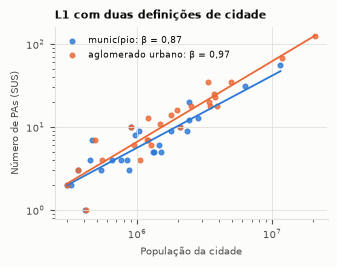

In [4]:
plt.rcParams.update({"font.size": 7.5, "axes.titlesize": 8})
fig, ax = plt.subplots(figsize=(3.4, 2.7))
r = cmp_[cmp_.versao == "SUS"].set_index("definicao_de_cidade")
for nome, pop_col, cor in [("município", "populacao_municipio", estilo.AZUL), ("aglomerado urbano", "populacao_aglomerado", estilo.LARANJA)]:
    d = agl[agl.pa_aglomerado_sus > 0] if nome != "município" else agl
    ncol = "pa_aglomerado_sus" if nome != "município" else "pa_municipio_sus"
    ax.scatter(d[pop_col], d[ncol], s=11, color=cor, alpha=.8, label=f"{nome}: β = {r.loc[nome, 'beta']:.2f}".replace(".", ","))
    xs = np.log10(np.array([d[pop_col].min(), d[pop_col].max()]))
    ax.plot(10**xs, 10**(r.loc[nome, "c"] + r.loc[nome, "beta"]*xs), color=cor, lw=1.3)
ax.set(xscale="log", yscale="log", xlabel="População da cidade", ylabel="Número de PAs (SUS)", title="L1 com duas definições de cidade")
ax.legend(fontsize=6.5, loc="upper left")
fig.tight_layout()
fig.savefig(FIG/"L1_aglomerado.pdf"); fig.savefig(FIG/"L1_aglomerado.png", dpi=220)
plt.show()
plt.rcParams.update({"font.size": 9.5, "axes.titlesize": 11})

In [5]:
a, b = r.loc["município"], r.loc["aglomerado urbano"]
display(Markdown(f"""
**Leitura (SUS).** Com o município, β = {a.beta:.2f} [{a.ic95_inferior:.2f}; {a.ic95_superior:.2f}]; com o aglomerado urbano do IBGE, β = {b.beta:.2f} [{b.ic95_inferior:.2f}; {b.ic95_superior:.2f}]
({int(b.n_capitais)} capitais). Se os dois intervalos se sobrepõem e ambos incluem 1, a conclusão do L1 (PAs crescendo quase proporcionalmente à população, com pequena economia de escala)
não depende de como a cidade é delimitada.
"""))


**Leitura (SUS).** Com o município, β = 0.87 [0.69; 1.02]; com o aglomerado urbano do IBGE, β = 0.97 [0.82; 1.15]
(26 capitais). Se os dois intervalos se sobrepõem e ambos incluem 1, a conclusão do L1 (PAs crescendo quase proporcionalmente à população, com pequena economia de escala)
não depende de como a cidade é delimitada.
